# Used Car Price Analysis using Data Wrangling and Preprocessing

## Problem Statement
Used-car listings contain information such as price, year, kilometres driven, fuel type, transmission, and engine details. The data may contain duplicate rows, missing values, inconsistent text, and values stored in the wrong data type.

This project cleans and explores the used-car dataset so that it is easier to understand how selling prices vary across different car features.

## Objectives
1. Inspect the dataset and understand its structure.
2. Find and handle duplicate rows, inconsistent text, and invalid values.
3. Convert columns into suitable data types and extract numeric specifications.
4. Explore selling prices using simple summaries and charts.
5. Save the cleaned dataset for future use.


## 2. Import Libraries

We will use pandas to work with the dataset, matplotlib to create charts, and seaborn to make the charts easier to read.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure chart appearance
sns.set_style("whitegrid")


## 3. Load the CSV File

In [2]:
file_path = "../data/raw/car_details_v3.csv"

try:
    df = pd.read_csv(file_path)
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print("File not found. Check the file_path and make sure the CSV is in data/raw/.")
    raise


Dataset loaded successfully.


## 4. Initial Data Inspection


In [3]:
expected_columns = [
    "name", "year", "selling_price", "km_driven", "fuel",
    "seller_type", "transmission", "owner", "mileage",
    "engine", "max_power", "torque", "seats"
]

missing_columns = []

for column in expected_columns:
    if column not in df.columns:
        missing_columns.append(column)

if len(missing_columns) > 0:
    print("The dataset is missing these required columns:", missing_columns)
    raise ValueError("Please check that the correct dataset has been loaded.")
else:
    print("All expected columns are present.")


All expected columns are present.


In [4]:
# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display available columns
print("\nColumn names:")
print(df.columns.tolist())

# Preview the dataset
print("\nFirst five rows:")
display(df.head())


Dataset shape: (8128, 13)

Column names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats']

First five rows:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [34]:
# Review column data types and non-null counts
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 1.6 MB


In [35]:
# Generate summary statistics for numeric columns
display(df.describe())


,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


In [37]:
# Count missing values in each column
print("Missing values:")
print(df.isnull().sum())


Missing values:
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64


In [38]:
# Count exact duplicate records
duplicate_count_before = df.duplicated().sum()
print("Exact duplicate rows:", duplicate_count_before)

Exact duplicate rows: 1202


## 5. Data Cleaning

We will create a working copy named `cleaned_df`. All cleaning will be done on this copy, so the original `df` remains unchanged.

In [9]:
cleaned_df = df.copy()

rows_before_cleaning = len(cleaned_df)
print("Rows before cleaning:", rows_before_cleaning)


Rows before cleaning: 8128


### 5.1 View and Remove Exact Duplicate Rows

First, display the duplicate rows and their count. Then remove exact duplicate rows. This removes only rows where every column has the same value.

In [10]:
# Show duplicate rows before removing them
duplicate_rows = cleaned_df[cleaned_df.duplicated()]

print("Number of duplicate rows:", len(duplicate_rows))
display(duplicate_rows.head(10))


Number of duplicate rows: 1202


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
291,Hyundai Grand i10 Sportz,2017,450000,35000,Petrol,Individual,Manual,First Owner,18.9 kmpl,1197 CC,82 bhp,114Nm@ 4000rpm,5.0
296,Maruti Swift VXI,2012,330000,50000,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,85.8 bhp,114Nm@ 4000rpm,5.0
370,Jaguar XE 2016-2019 2.0L Diesel Prestige,2017,2625000,9000,Diesel,Dealer,Automatic,First Owner,13.6 kmpl,1999 CC,177 bhp,430Nm@ 1750-2500rpm,5.0
371,Lexus ES 300h,2019,5150000,20000,Petrol,Dealer,Automatic,First Owner,22.37 kmpl,2487 CC,214.56 bhp,202Nm@ 3600-5200rpm,5.0
372,Jaguar XF 2.0 Diesel Portfolio,2017,3200000,45000,Diesel,Dealer,Automatic,First Owner,19.33 kmpl,1999 CC,177 bhp,430Nm@ 1750-2500rpm,5.0
387,Skoda Rapid 1.6 MPI AT Elegance,2016,645000,11000,Petrol,Dealer,Automatic,First Owner,14.3 kmpl,1598 CC,103.5 bhp,153Nm@ 3800rpm,5.0
409,Jaguar XE 2016-2019 2.0L Diesel Prestige,2017,2625000,9000,Diesel,Dealer,Automatic,First Owner,13.6 kmpl,1999 CC,177 bhp,430Nm@ 1750-2500rpm,5.0
410,Lexus ES 300h,2019,5150000,20000,Petrol,Dealer,Automatic,First Owner,22.37 kmpl,2487 CC,214.56 bhp,202Nm@ 3600-5200rpm,5.0
411,Jaguar XF 2.0 Diesel Portfolio,2017,3200000,45000,Diesel,Dealer,Automatic,First Owner,19.33 kmpl,1999 CC,177 bhp,430Nm@ 1750-2500rpm,5.0
412,Tata Safari Storme EX,2015,503000,110000,Diesel,Individual,Manual,First Owner,14.1 kmpl,2179 CC,147.94 bhp,320Nm@ 1500-3000rpm,7.0


In [11]:
# Remove exact duplicate rows
cleaned_df = cleaned_df.drop_duplicates()

duplicates_removed = rows_before_cleaning - len(cleaned_df)

print("Duplicate rows removed:", duplicates_removed)
print("Rows after removing duplicates:", len(cleaned_df))


Duplicate rows removed: 1202
Rows after removing duplicates: 6926


### 5.2 Trim Spaces and Standardize Text Categories

Extra spaces can make the same category appear as two different values. We will remove spaces at the beginning and end of text values. Category columns will also be changed to title case, for example `diesel` becomes `Diesel`.

The original `name` and `torque` fields are kept as text.

In [12]:
# Text columns that should have extra spaces removed
text_columns = [
    "name", "fuel", "seller_type", "transmission",
    "owner", "mileage", "engine", "max_power", "torque"
]

for column in text_columns:
    cleaned_df[column] = cleaned_df[column].astype("string").str.strip()

# Standardize category capitalization
category_columns = ["fuel", "seller_type", "transmission", "owner"]

for column in category_columns:
    cleaned_df[column] = cleaned_df[column].str.title()

print("Text values have been trimmed and categories standardized.")
display(cleaned_df[category_columns].head())


Text values have been trimmed and categories standardized.


,fuel,seller_type,transmission,owner
0,Diesel,Individual,Manual,First Owner
1,Diesel,Individual,Manual,Second Owner
2,Petrol,Individual,Manual,Third Owner
3,Diesel,Individual,Manual,First Owner
4,Petrol,Individual,Manual,First Owner


### 5.3 Convert Main Columns to Numeric Values

The `year`, `selling_price`, `km_driven`, and `seats` columns should contain numbers. `errors="coerce"` changes values that cannot be converted into numbers to missing values (`NaN`). These missing values will be checked later; they will not be replaced with zero.

In [13]:
numeric_columns = ["year", "selling_price", "km_driven", "seats"]

for column in numeric_columns:
    cleaned_df[column] = pd.to_numeric(cleaned_df[column], errors="coerce")

print("Updated data types:")
print(cleaned_df[numeric_columns].dtypes)


Updated data types:
year               int64
selling_price      int64
km_driven          int64
seats            float64
dtype: object


### 5.4 Extract Numeric Values from Car Specifications

The `mileage`, `engine`, and `max_power` columns may contain numbers along with units such as `kmpl`, `CC`, or `bhp`.

We will extract the numeric part into new columns:
- `mileage_value`: mileage value, usually in km/litre.
- `engine_cc`: engine capacity in CC.
- `max_power_bhp`: maximum power in bhp.

The original text columns are preserved. This keeps the original information available for reference.

In [14]:
cleaned_df["mileage_value"] = pd.to_numeric(
    cleaned_df["mileage"].str.extract(r"([0-9]+\.?[0-9]*)", expand=False),
    errors="coerce"
)

cleaned_df["engine_cc"] = pd.to_numeric(
    cleaned_df["engine"].str.extract(r"([0-9]+\.?[0-9]*)", expand=False),
    errors="coerce"
)

cleaned_df["max_power_bhp"] = pd.to_numeric(
    cleaned_df["max_power"].str.extract(r"([0-9]+\.?[0-9]*)", expand=False),
    errors="coerce"
)

display(cleaned_df[
    ["mileage", "mileage_value", "engine", "engine_cc",
     "max_power", "max_power_bhp"]
].head())


,mileage,mileage_value,engine,engine_cc,max_power,max_power_bhp
0,23.4 kmpl,23.4,1248 CC,1248,74 bhp,74.0
1,21.14 kmpl,21.14,1498 CC,1498,103.52 bhp,103.52
2,17.7 kmpl,17.7,1497 CC,1497,78 bhp,78.0
3,23.0 kmpl,23.0,1396 CC,1396,90 bhp,90.0
4,16.1 kmpl,16.1,1298 CC,1298,88.2 bhp,88.2


### 5.5 Keep Torque as Text

Torque values can have different formats and units. To keep this project simple and avoid incorrect conversions, we will keep `torque` as a text column. No numeric torque conversion is performed.

In [15]:
print("Torque data type:", cleaned_df["torque"].dtype)
display(cleaned_df[["torque"]].head())


Torque data type: string


,torque
0,190Nm@ 2000rpm
1,250Nm@ 1500-2500rpm
2,"12.7@ 2,700(kgm@ rpm)"
3,22.4 kgm at 1750-2750rpm
4,"11.5@ 4,500(kgm@ rpm)"


### 5.6 Check Missing Values After Cleaning

Some values may become missing when text cannot be converted into numbers or when a specification has no numeric value. We will report missing values and leave them as missing.

We will not replace missing values with zero because zero could represent a real measurement and would change the meaning of the data.

In [16]:
missing_after_cleaning = cleaned_df.isnull().sum()

print("Missing values after cleaning:")
print(missing_after_cleaning)


Missing values after cleaning:
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          208
engine           208
max_power        205
torque           209
seats            208
mileage_value    208
engine_cc        208
max_power_bhp    206
dtype: int64


### 5.7 Check Values That May Be Invalid

Before removing anything, we will identify rows with:
- Selling price less than or equal to zero.
- Kilometres driven below zero.
- Year or number of seats less than or equal to zero.

These checks help identify values that are not sensible for a used-car listing. The rows are displayed and counted before a decision is made.

In [17]:
invalid_price_rows = cleaned_df[cleaned_df["selling_price"].notnull() &
                                  (cleaned_df["selling_price"] <= 0)]

invalid_km_rows = cleaned_df[cleaned_df["km_driven"].notnull() &
                             (cleaned_df["km_driven"] < 0)]

invalid_year_rows = cleaned_df[cleaned_df["year"].notnull() &
                               (cleaned_df["year"] <= 0)]

invalid_seats_rows = cleaned_df[cleaned_df["seats"].notnull() &
                                (cleaned_df["seats"] <= 0)]

print("Rows with selling price <= 0:", len(invalid_price_rows))
print("Rows with kilometres below 0:", len(invalid_km_rows))
print("Rows with year <= 0:", len(invalid_year_rows))
print("Rows with seats <= 0:", len(invalid_seats_rows))

print("\nExamples of rows with invalid selling prices:")
display(invalid_price_rows.head())

print("Examples of rows with invalid kilometres:")
display(invalid_km_rows.head())

print("Examples of rows with invalid years:")
display(invalid_year_rows.head())

print("Examples of rows with invalid seats:")
display(invalid_seats_rows.head())


Rows with selling price <= 0: 0
Rows with kilometres below 0: 0
Rows with year <= 0: 0
Rows with seats <= 0: 0

Examples of rows with invalid selling prices:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,mileage_value,engine_cc,max_power_bhp


Examples of rows with invalid kilometres:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,mileage_value,engine_cc,max_power_bhp


Examples of rows with invalid years:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,mileage_value,engine_cc,max_power_bhp


Examples of rows with invalid seats:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,mileage_value,engine_cc,max_power_bhp


### 5.8 Handle Clearly Invalid Values

For this project, rows with a non-positive selling price, negative kilometres, non-positive year, or non-positive seat count will be removed because these values are not sensible for the analysis.

Rows with missing values are not removed by this step. Rows with unusually high but possible prices or kilometres are also kept for investigation.

In [18]:
invalid_row_count_before_removal = len(
    invalid_price_rows.index.union(invalid_km_rows.index)
    .union(invalid_year_rows.index)
    .union(invalid_seats_rows.index)
)

invalid_indexes = (
    invalid_price_rows.index
    .union(invalid_km_rows.index)
    .union(invalid_year_rows.index)
    .union(invalid_seats_rows.index)
)

cleaned_df = cleaned_df.drop(index=invalid_indexes)

invalid_rows_removed = len(invalid_indexes)

print("Invalid rows identified:", invalid_row_count_before_removal)
print("Invalid rows removed:", invalid_rows_removed)
print("Rows remaining:", len(cleaned_df))


Invalid rows identified: 0
Invalid rows removed: 0
Rows remaining: 6926


### 5.9 Investigate Outliers

Outliers are values that are much higher or lower than most of the other values. Some used cars can genuinely have high prices or high kilometres, so an unusual value is not automatically an error.

We will use boxplots and the IQR method to flag possible outliers in selling price and kilometres driven. The flagged rows will be kept.

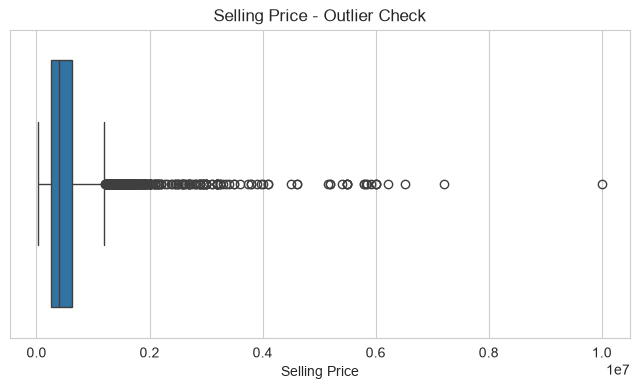

In [19]:
# Boxplot for selling price
plt.figure(figsize=(8, 4))
sns.boxplot(x=cleaned_df["selling_price"])
plt.title("Selling Price - Outlier Check")
plt.xlabel("Selling Price")
plt.show()


**Observation prompt:** What do you notice about the selling-price boxplot? Are there points far away from the main group? Write your observation after running the chart.

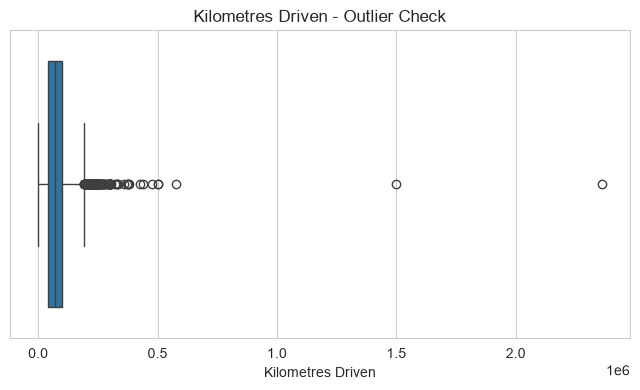

In [20]:
# Boxplot for kilometres driven
plt.figure(figsize=(8, 4))
sns.boxplot(x=cleaned_df["km_driven"])
plt.title("Kilometres Driven - Outlier Check")
plt.xlabel("Kilometres Driven")
plt.show()


**Observation prompt:** Are there cars with much higher kilometres driven than most listings? Do you think these values could still be valid? Explain briefly.

In [21]:
# IQR method for selling price
price_q1 = cleaned_df["selling_price"].quantile(0.25)
price_q3 = cleaned_df["selling_price"].quantile(0.75)
price_iqr = price_q3 - price_q1

price_lower_limit = price_q1 - 1.5 * price_iqr
price_upper_limit = price_q3 + 1.5 * price_iqr

price_outliers = cleaned_df[
    (cleaned_df["selling_price"] < price_lower_limit) |
    (cleaned_df["selling_price"] > price_upper_limit)
]

# IQR method for kilometres driven
km_q1 = cleaned_df["km_driven"].quantile(0.25)
km_q3 = cleaned_df["km_driven"].quantile(0.75)
km_iqr = km_q3 - km_q1

km_lower_limit = km_q1 - 1.5 * km_iqr
km_upper_limit = km_q3 + 1.5 * km_iqr

km_outliers = cleaned_df[
    (cleaned_df["km_driven"] < km_lower_limit) |
    (cleaned_df["km_driven"] > km_upper_limit)
]

print("Possible selling-price outliers:", len(price_outliers))
print("Selling-price IQR limits:", price_lower_limit, "to", price_upper_limit)

print("\nPossible kilometres-driven outliers:", len(km_outliers))
print("Kilometres IQR limits:", km_lower_limit, "to", km_upper_limit)

print("\nNo outliers are removed automatically.")


Possible selling-price outliers: 328
Selling-price IQR limits: -325250.0 to 1208750.0

Possible kilometres-driven outliers: 167
Kilometres IQR limits: -50000.0 to 190000.0

No outliers are removed automatically.


## 6. Data Transformation

### 6.1 Create Car Age

Car age is calculated using a reference year based on the dataset itself, not the current year. We first check the maximum valid year in the cleaned dataset. That maximum year is used as the reference year so that the calculation matches the period covered by the listings.

The new column `car_age_years` represents the difference between the reference year and the car's model year.

In [22]:
latest_year = cleaned_df["year"].max()

if pd.isna(latest_year):
    raise ValueError("Car age cannot be calculated because there are no valid year values.")

reference_year = int(latest_year)

print("Latest year found in the dataset:", reference_year)
print("Reference year used for car age:", reference_year)

cleaned_df["car_age_years"] = reference_year - cleaned_df["year"]

display(cleaned_df[["year", "car_age_years"]].head())


Latest year found in the dataset: 2020
Reference year used for car age: 2020


,year,car_age_years
0,2014,6
1,2014,6
2,2006,14
3,2010,10
4,2007,13


## 7. Exploratory Data Analysis (EDA)

In this section, we will use simple charts and group summaries to explore how selling prices vary across car features. The charts calculate their results from the cleaned dataset when the notebook is run.

**Note:** Write your own observations below each chart. Do not assume a result before viewing the chart.

### 7.1 Selling Price Distribution

This histogram shows how selling prices are distributed across the listings.

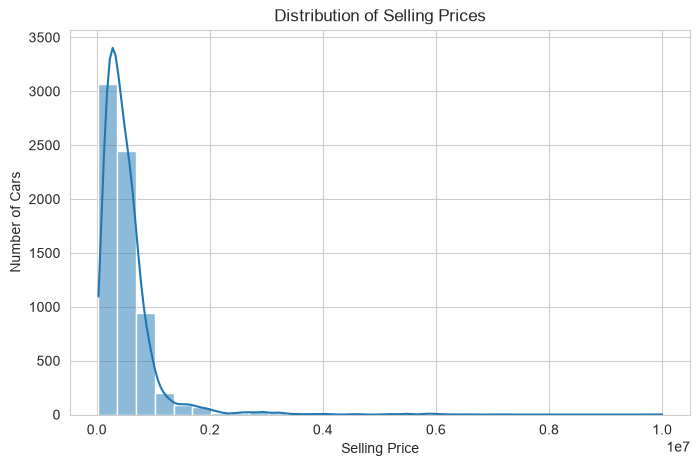

In [23]:
plt.figure(figsize=(8, 5))
sns.histplot(data=cleaned_df, x="selling_price", bins=30, kde=True)
plt.title("Distribution of Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.show()


**Observation prompt:** Which selling-price range contains the largest number of cars? Does the distribution look balanced or skewed?

### 7.2 Selling Price by Fuel Type

This boxplot compares selling prices for different fuel types.

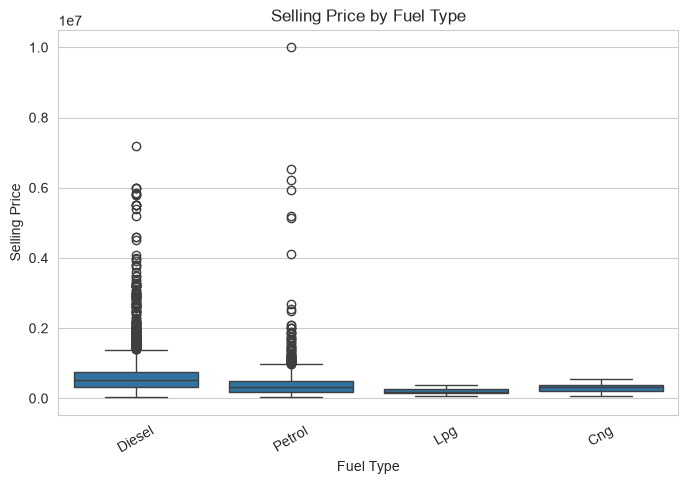

In [24]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=cleaned_df, x="fuel", y="selling_price")
plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.xticks(rotation=30)
plt.show()


**Observation prompt:** Compare the price ranges across fuel types. Which fuel types appear to have higher or lower median prices?

### 7.3 Selling Price by Transmission

This chart compares the selling prices of manual and automatic cars, where those categories are present in the data.

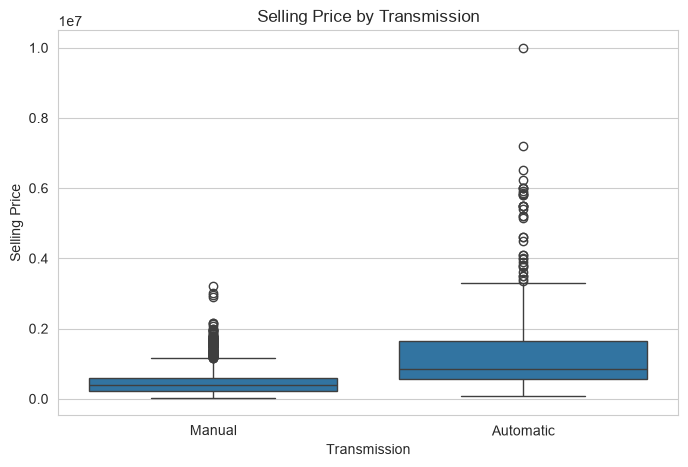

In [25]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=cleaned_df, x="transmission", y="selling_price")
plt.title("Selling Price by Transmission")
plt.xlabel("Transmission")
plt.ylabel("Selling Price")
plt.show()


**Observation prompt:** How do the price distributions compare between transmission types? Mention any visible difference in median or spread.

### 7.4 Selling Price Versus Kilometres Driven

This scatter plot helps explore whether selling price changes with the number of kilometres driven.

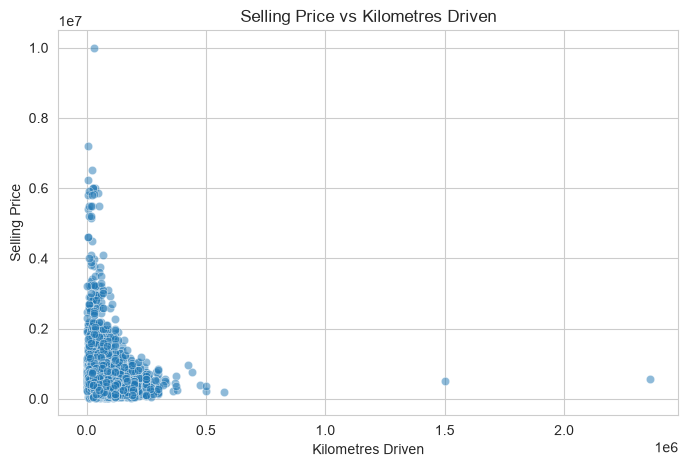

In [26]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=cleaned_df, x="km_driven", y="selling_price", alpha=0.5)
plt.title("Selling Price vs Kilometres Driven")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price")
plt.show()


**Observation prompt:** Is there a visible relationship between kilometres driven and selling price? Are there any unusual points?

### 7.5 Selling Price Versus Car Year

This scatter plot compares selling price with the car's model year. Newer model years may have different price patterns from older model years.

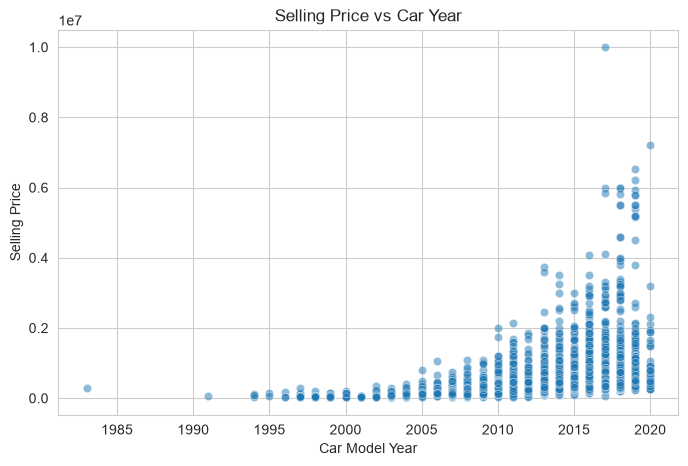

In [27]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=cleaned_df, x="year", y="selling_price", alpha=0.5)
plt.title("Selling Price vs Car Year")
plt.xlabel("Car Model Year")
plt.ylabel("Selling Price")
plt.show()


**Observation prompt:** What happens to selling prices as the model year changes? Describe the pattern you can see.

### 7.6 Median Selling Price by Fuel Type

The median is used because it is less affected by very high or very low prices than the mean.

In [28]:
median_price_by_fuel = cleaned_df.groupby("fuel")["selling_price"].median()

print("Median selling price by fuel type:")
display(median_price_by_fuel.sort_values(ascending=False))


Median selling price by fuel type:


fuel
Diesel    520000.0
Cng       320000.0
Petrol    310000.0
Lpg       195500.0
Name: selling_price, dtype: float64

### 7.7 Median Selling Price by Transmission

This summary shows the median selling price for each transmission category.

In [29]:
median_price_by_transmission = cleaned_df.groupby("transmission")["selling_price"].median()

print("Median selling price by transmission:")
display(median_price_by_transmission.sort_values(ascending=False))


Median selling price by transmission:


transmission
Automatic    850000.0
Manual       385000.0
Name: selling_price, dtype: float64

### 7.8 Median Selling Price by Fuel Type and Transmission

This combined summary compares the median selling price for each fuel and transmission combination.

In [30]:
median_price_by_fuel_transmission = cleaned_df.groupby(
    ["fuel", "transmission"]
)["selling_price"].median().unstack()

print("Median selling price by fuel type and transmission:")
display(median_price_by_fuel_transmission)


Median selling price by fuel type and transmission:


transmission,Automatic,Manual
fuel,,
Cng,NaN,320000.0
Diesel,1350000.0,495000.0
Lpg,NaN,195500.0
Petrol,580000.0,300000.0


## 8. Data-Quality Summary

This section brings together the main data-quality checks. It reports the original row count, rows remaining after cleaning, duplicates removed, invalid rows removed, and missing values in the cleaned dataset.

In [31]:
rows_after_cleaning = len(cleaned_df)

print("DATA-QUALITY SUMMARY")
print("--------------------")
print("Rows before cleaning:", rows_before_cleaning)
print("Rows after cleaning:", rows_after_cleaning)
print("Duplicate rows removed:", duplicates_removed)
print("Invalid rows removed:", invalid_rows_removed)

print("\nMissing values in cleaned dataset:")
print(cleaned_df.isnull().sum())

print("\nTotal missing values in cleaned dataset:",
      cleaned_df.isnull().sum().sum())


DATA-QUALITY SUMMARY
--------------------
Rows before cleaning: 8128
Rows after cleaning: 6926
Duplicate rows removed: 1202
Invalid rows removed: 0

Missing values in cleaned dataset:
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          208
engine           208
max_power        205
torque           209
seats            208
mileage_value    208
engine_cc        208
max_power_bhp    206
car_age_years      0
dtype: int64

Total missing values in cleaned dataset: 1660


## 9. Save the Cleaned Dataset

The cleaned data will be saved to `../data/processed/cleaned_car_data.csv`.

The code creates the `processed` folder if it does not already exist. The original CSV file is not overwritten.

In [32]:
import os

output_folder = "../data/processed"
output_file = os.path.join(output_folder, "cleaned_car_data.csv")

# Create the output folder if it does not exist
os.makedirs(output_folder, exist_ok=True)

# Save the cleaned dataset
cleaned_df.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully.")
print("Saved file location:", output_file)


Cleaned dataset saved successfully.
Saved file location: ../data/processed\cleaned_car_data.csv


In [33]:
# Check that the saved file exists
if os.path.exists(output_file):
    print("File check successful. The cleaned CSV file is available.")
else:
    print("File was not found. Please check the output path.")


File check successful. The cleaned CSV file is available.
